## Functions

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Use np.trapz on older NumPy versions that do not have np.trapezoid
if not hasattr(np, "trapezoid"):
    np.trapezoid = np.trapz


# ---------------- Perception maps ---------------------
# Cubic family phi_c
def Phi_c(y, a=1.05):
    u = 2.0*y - 1.0
    return 0.5*(1.0 + a*u + (1.0 - a)*u**3)

# Sine family phi_s
def Phi_s(y, a=4):
    return np.clip(y - np.sin(2.0*np.pi*a*y - np.pi*a)/(2.0*np.pi*a), 0, 1)

# Linear map phi_1(x) = 0.4 + 0.2x
def Phi_1(y):
    return 0.4 + 0.2*y

# Non-monotone map phi_2(x) = x + sin(4 pi x)/4
def Phi_2(y):
    return np.clip(y + 0.25*np.sin(4.0*np.pi*y), 0, 1)


# ---------------- Forward solver ----------------------
# Precompute kernel values and the grid cells where post-interaction opinions land
def build(Phi):
    phij  = Phi(xgrid)
    Theta = theta_n(xgrid[:, None], phij[None, :])              # theta(x_i, phi(x_j))
    Xp    = xgrid[:, None] - gamma*P(xgrid)[:, None]*(xgrid[:, None] - phij[None, :])
    Xp    = np.clip(Xp, xgrid[0], xgrid[-1])                    # post-interaction target
    kf    = (Xp - xgrid[0]) / dx
    k     = np.clip(np.floor(kf).astype(int), 0, N-2)
    t     = kf - k                                              # deposition fraction
    return Theta.ravel(), k.ravel(), t.ravel()

# Right-hand side of the density equation: gain minus loss on the grid
def make_rhs(Theta, k, t):
    kp1, w_lo, w_hi = k+1, 1.0 - t, t
    def rhs(f):
        raw  = Theta * np.repeat(f, N) * np.tile(f, N)          # theta_ij * f_i * f_j
        loss = raw.reshape(N, N).sum(axis=1)                    # mass leaving cell i
        gain = (np.bincount(k,   raw*w_lo, minlength=N)         # mass-conserving scatter
              + np.bincount(kp1, raw*w_hi, minlength=N))
        return 2.0*dx*(gain - loss)
    return rhs

# One RK4 step, followed by clipping negative values and renormalizing the mass
def rk4(f, rhs, dt):
    k1 = rhs(f); k2 = rhs(f + 0.5*dt*k1)
    k3 = rhs(f + 0.5*dt*k2); k4 = rhs(f + dt*k3)
    fnew = f + dt*(k1 + 2*k2 + 2*k3 + k4)/6.0
    fnew = np.maximum(fnew, 0.0)
    mass = np.trapezoid(fnew, xgrid)
    if mass <= 1e-12 or not np.isfinite(mass):
        return f.copy()
    return fnew / mass


## Density-based dynamics

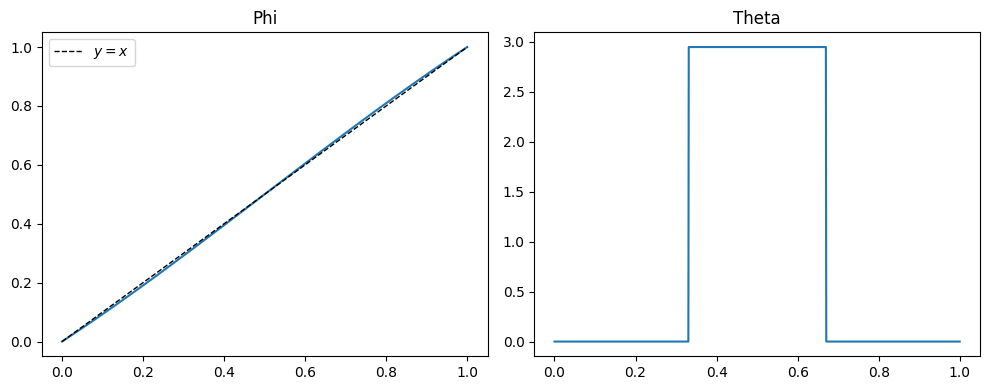

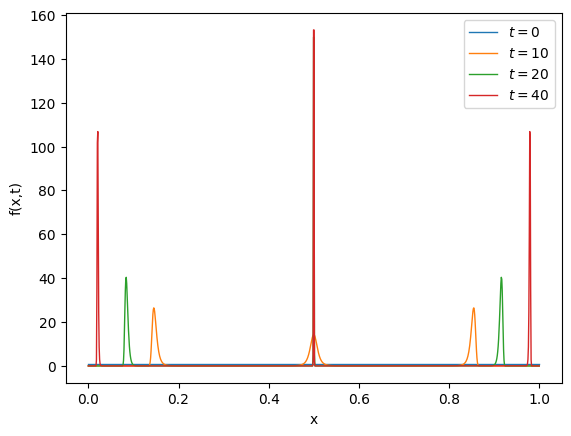

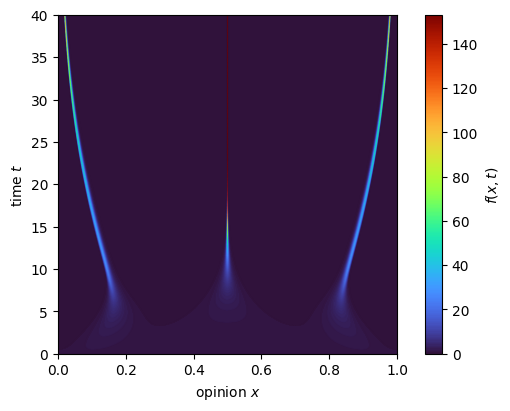

In [2]:
# Density-based dynamics

# ---------------- Numerical parameters ----------------
N     = 1000                       # grid size
xgrid = np.linspace(0.0, 1.0, N)
dx    = xgrid[1] - xgrid[0]
dt    = 0.02                       # time step
T     = 40.0                       # stop time
steps = int(T / dt)
gamma = 0.4
eps   = 0.17                       # confidence bound

# ---------------- Perception map ----------------------
Phi = Phi_c                        # Phi_c, Phi_s, Phi_1 or Phi_2

# ---------------- Kernel theta ------------------------
# Bounded confidence kernel
def theta(x, y):
    return (np.abs(x - y) <= eps).astype(float)

# Normalize the kernel
mid     = xgrid[N//2]
norm    = np.trapezoid(theta(mid, xgrid), xgrid)
theta_n = lambda x, y: theta(x, y) / norm

# ---------------- Susceptibility P --------------------
def P(x):
    return np.ones_like(x)

# ---------------- Initial distribution ----------------
f = np.ones_like(xgrid)
f = f / np.trapezoid(f, xgrid)

# ---------------- Diagnostics: Phi, theta -------------
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].plot(xgrid, Phi(xgrid))
axs[0].plot(xgrid, xgrid, 'k--', lw=1, label=r'$y=x$')
axs[0].set_title('Phi'); axs[0].legend()
axs[1].plot(xgrid, theta_n(mid, xgrid))
axs[1].set_title('Theta')
plt.tight_layout()
plt.show()

# ---------------- Time stepping -----------------------
Theta, k, t = build(Phi)
rhs = make_rhs(Theta, k, t)

snapshots = [f.copy()]
for n in range(steps):
    f = rk4(f, rhs, dt)
    snapshots.append(f.copy())

data  = np.array(snapshots)
tvals = np.arange(data.shape[0]) * dt

# ---------------- Line plot of a few snapshots --------
for ti in [0, T/4, T/2, T]:
    j = min(int(round(ti/dt)), len(data)-1)
    plt.plot(xgrid, data[j], lw=1.0, label=rf'$t={ti:g}$')
plt.xlabel("x"); plt.ylabel("f(x,t)")
plt.legend()
plt.show()

# ---------------- Space-time heat map -----------------
fig, ax = plt.subplots(figsize=(5, 4), constrained_layout=True)
pcm = ax.pcolormesh(xgrid, tvals, data, cmap='turbo',
                    shading='gouraud', rasterized=True, vmin=0)
ax.set_xlabel(r'opinion $x$')
ax.set_ylabel(r'time $t$')
cb = fig.colorbar(pcm, ax=ax)
cb.set_label(r'$f(x,t)$')
plt.show()


## Agent-based dynamics

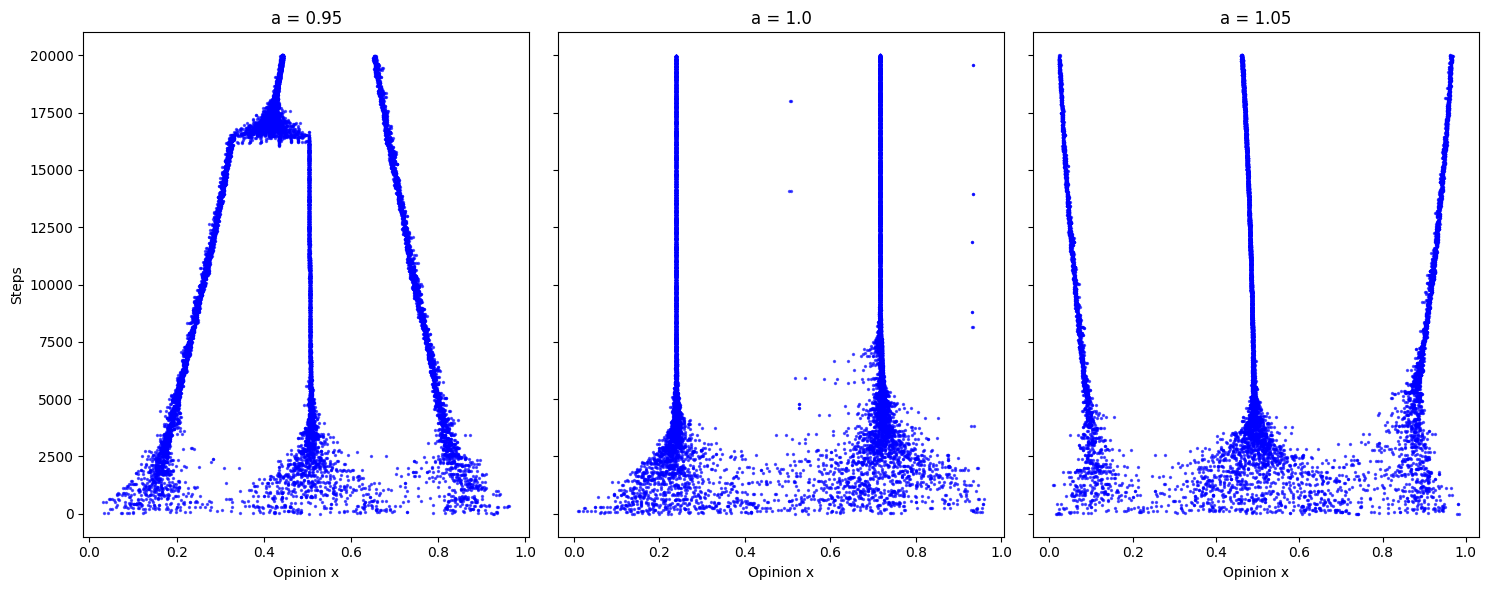

In [4]:
# Agent-based dynamics

# Random pairwise interactions; each agent updates only if it perceives the other within eps
def simulate(N=200, steps=20000, gamma=0.4, phi=lambda x: x, eps=0.17, x0=None, seed=None):
    rng = np.random.default_rng(seed)
    x = rng.uniform(0, 1, N) if x0 is None else np.array(x0, dtype=float)
    events_t, events_x = [], []

    for t in range(steps):
        i, j = rng.choice(N, size=2, replace=True)
        xi, xj = x[i], x[j]
        if np.abs(xi - phi(xj)) < eps:
            x[i] = (1 - gamma)*xi + gamma*phi(xj)
            events_t.append(t); events_x.append(x[i])
        if np.abs(xj - phi(xi)) < eps:
            x[j] = (1 - gamma)*xj + gamma*phi(xi)
            events_t.append(t); events_x.append(x[j])

    return x, np.array(events_t), np.array(events_x)


# ---------------- Parameters --------------------------
N_agents   = 200
steps_ab   = 20000
gamma_ab   = 0.4
eps_ab     = 0.17
a_values   = [0.95, 1.0, 1.05]

# ---------------- Run and plot ------------------------
fig, axes = plt.subplots(1, len(a_values), figsize=(15, 6), sharey=True)
for ax, a in zip(axes, a_values):
    phi = lambda y, a=a: Phi_c(y, a)
    x_final, ev_t, ev_x = simulate(N=N_agents, steps=steps_ab, gamma=gamma_ab,
                                   phi=phi, eps=eps_ab)
    ax.scatter(ev_x, ev_t, s=2, color='blue', alpha=0.6)
    ax.set_xlabel("Opinion x")
    ax.set_title(f"a = {a}")
axes[0].set_ylabel("Steps")
plt.tight_layout()
plt.show()
